# Lab 6: Linear Regression with
## Hypoxia data

------



Lab TA: Lee Ochs

In [1]:
#load the correct environment/kernel (python 3 ipykernel)
#mine uses the base enviornment 
#if package does not load correctly, close notebook, type "conda activate base" in ur terminal, then type "jupyter notebook"
import pandas as pd #data frame
import numpy as np  #matrix, numbers 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## Lab Objectives:

1.	Understand underlying cause of hypoxia 
2.	Calculate linear regression variables and confidence intervals for TX_LA shelf hypoxia data
3.	 Compare the regression with ANOVA 
4.	Data manipulation (adding data to existing data frame, data sorting)

In [6]:
#import the data
hypoxia = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab6/lab6_data_hypoxia.txt', sep= "\t")

print(hypoxia.head())

   Year  Area_km2  discharge_m3persecond  nitrate_mtpermonth
0  1985      9774                  26200              112000
1  1986      9432                  20500              121000
2  1987      6688                  17800               87400
3  1990      9260                  36000              146000
4  1991     11920                  43600              189000


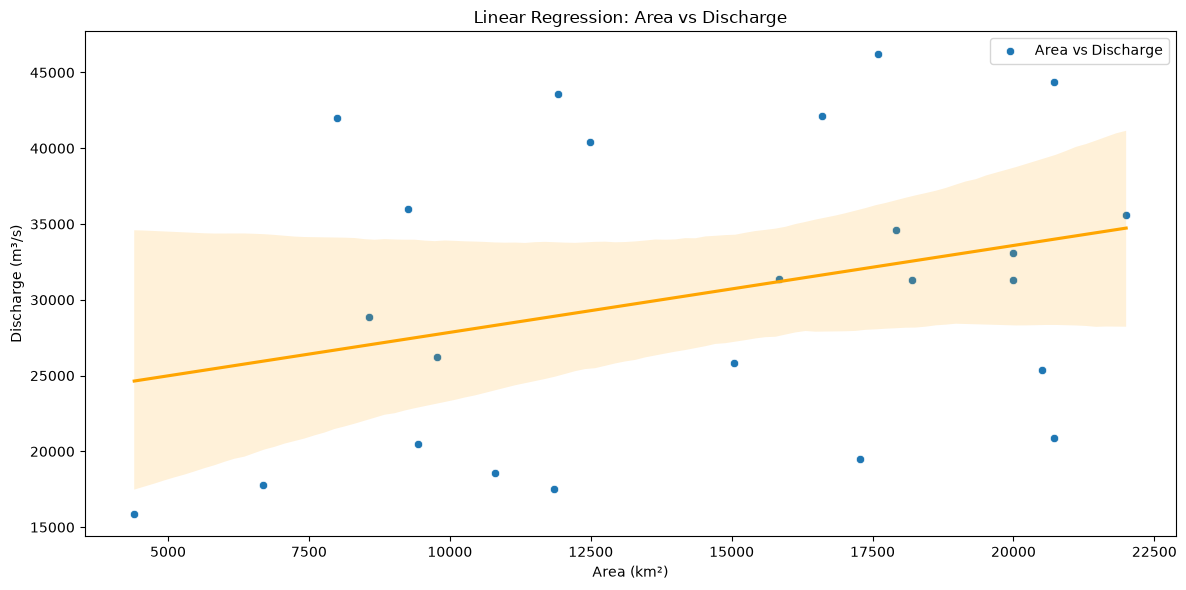

In [9]:
#practise, plot linear regression line with 95% confidence interval
#discharge vs area
plt.figure(figsize=(12, 6))
sns.scatterplot(data=hypoxia, x= 'Area_km2', y= 'discharge_m3persecond', label='Area vs Discharge'  )
sns.regplot(data=hypoxia, x= 'Area_km2', y= 'discharge_m3persecond', label='Area vs Discharge' , ci=95, scatter=False, color='orange' )
plt.xlabel('Area (km²)')
plt.ylabel('Discharge (m³/s)')
plt.title('Linear Regression: Area vs Discharge')

plt.tight_layout()
plt.show()


Get ANOVA information of the linear regression model


In [10]:

#last class we calculated the slope a, intercpet b, r value, p value, standard error.
from scipy import stats
#calculate the regression model 
stats.linregress(hypoxia['discharge_m3persecond'], hypoxia['Area_km2'])




LinregressResult(slope=np.float64(0.16906364335814064), intercept=np.float64(9263.775166329811), rvalue=np.float64(0.3113366716059131), pvalue=np.float64(0.1386323907517686), stderr=np.float64(0.11001937845348758), intercept_stderr=np.float64(3498.5196493897392))

In [12]:
#we will use a new funciton
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Fit a simple linear regression model: Area ~ Discharge
#ols is ordinary least squares
model = ols('Area_km2 ~ discharge_m3persecond', data=hypoxia).fit()


print(model.summary())


                            OLS Regression Results                            
Dep. Variable:               Area_km2   R-squared:                       0.097
Model:                            OLS   Adj. R-squared:                  0.056
Method:                 Least Squares   F-statistic:                     2.361
Date:                Wed, 07 Oct 2026   Prob (F-statistic):              0.139
Time:                        15:24:54   Log-Likelihood:                -237.76
No. Observations:                  24   AIC:                             479.5
Df Residuals:                      22   BIC:                             481.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept              9263.77

## Anatomy of the data
### Goodness-of-the-fit
- R-squared (0.097) → ~9.7% of the variance in area is explained by discharge.

### F-statistic
$$
F = \frac{\text{Mean Square Model}}{\text{Mean Square Residue}} 
$$
- Ratio between the variance explained by the model vs residual (1, >1,<1) sort of like signal-noise-ratio
- F = 2.361 
- p = 0.139 → > 0.05, so the model is not statistically significant overall.

### This means discharge alone does not significantly predict area at the 0.05 level.

In [13]:
#if we just want the anova table
anova_table = sm.stats.anova_lm(model, typ=2)
#typ 2 is the type of anova, use type 2 for simple linear regression
print(anova_table)


#variation explained by the model
#degrees of freedom, df = 1(we used one predictor)

                             sum_sq    df         F    PR(>F)
discharge_m3persecond  6.073913e+07   1.0  2.361359  0.138632
Residual               5.658863e+08  22.0       NaN       NaN


In [14]:
#the data we had is incomplete and some outliers were excluded 
#so lets go to the reference and find the missing year and add that
#create a copy of the data frame hypoxia
hypoxia_copy = hypoxia.copy()
#we do that when we wanna keep the original data frame unchanged
print(hypoxia_copy)
#now we add the missing year 1988

    Year  Area_km2  discharge_m3persecond  nitrate_mtpermonth
0   1985      9774                  26200              112000
1   1986      9432                  20500              121000
2   1987      6688                  17800               87400
3   1990      9260                  36000              146000
4   1991     11920                  43600              189000
5   1992     10804                  18600              104000
6   1993     17600                  46200              214000
7   1994     16600                  42100              130000
8   1995     18200                  31300              142000
9   1996     17920                  34600              146000
10  1997     15840                  31400              122000
11  1998     12480                  40400              170000
12  1999     20000                  33100              182000
13  2000      4400                  15900               62500
14  2001     20720                  20900              123000
15  2002

In [15]:
#create a new data frame with data
new_data = pd.DataFrame({
    'Year': [1988],
    'nitrate_mtpermonth': [150000],
    'discharge_m3persecond': [2500],
    'Area_km2': [8000]
})
print(new_data)

   Year  nitrate_mtpermonth  discharge_m3persecond  Area_km2
0  1988              150000                   2500      8000


In [16]:
#now use pd.concat to combine the two data frames
hypoxia_full = pd.concat([hypoxia_copy, new_data], ignore_index=True)
#ignore_index=True will reset the index so it goes from 0 to n-1
print(hypoxia_full)

    Year  Area_km2  discharge_m3persecond  nitrate_mtpermonth
0   1985      9774                  26200              112000
1   1986      9432                  20500              121000
2   1987      6688                  17800               87400
3   1990      9260                  36000              146000
4   1991     11920                  43600              189000
5   1992     10804                  18600              104000
6   1993     17600                  46200              214000
7   1994     16600                  42100              130000
8   1995     18200                  31300              142000
9   1996     17920                  34600              146000
10  1997     15840                  31400              122000
11  1998     12480                  40400              170000
12  1999     20000                  33100              182000
13  2000      4400                  15900               62500
14  2001     20720                  20900              123000
15  2002

In [17]:
#now we can sort by year
hypoxia_full = hypoxia_full.sort_values(by='Year')
print(hypoxia_full)


    Year  Area_km2  discharge_m3persecond  nitrate_mtpermonth
0   1985      9774                  26200              112000
1   1986      9432                  20500              121000
2   1987      6688                  17800               87400
24  1988      8000                   2500              150000
3   1990      9260                  36000              146000
4   1991     11920                  43600              189000
5   1992     10804                  18600              104000
6   1993     17600                  46200              214000
7   1994     16600                  42100              130000
8   1995     18200                  31300              142000
9   1996     17920                  34600              146000
10  1997     15840                  31400              122000
11  1998     12480                  40400              170000
12  1999     20000                  33100              182000
13  2000      4400                  15900               62500
14  2001

In [18]:
#to extract the data between 1985 to 1995
#df[], and put conditions in () into the []
hypoxia_85_95 = hypoxia_full[(hypoxia_full['Year'] >= 1985) & (hypoxia_full['Year'] <= 1995)]
print(hypoxia_85_95)

    Year  Area_km2  discharge_m3persecond  nitrate_mtpermonth
0   1985      9774                  26200              112000
1   1986      9432                  20500              121000
2   1987      6688                  17800               87400
24  1988      8000                   2500              150000
3   1990      9260                  36000              146000
4   1991     11920                  43600              189000
5   1992     10804                  18600              104000
6   1993     17600                  46200              214000
7   1994     16600                  42100              130000
8   1995     18200                  31300              142000


In [ ]:
#practise, extract all the data from hypoxia_full but area is larger than 7000

#practise, extract all the data from hypoxia_full but year is not 1990 (!=)


In [22]:
#as you think, we can use the concat to any two data frames with same columns
#practise: try bind the original hypoxia data frame to itself
hypoxia_doubled = pd.concat((hypoxia_full, hypoxia_full))
print(hypoxia_doubled)

    Year  Area_km2  discharge_m3persecond  nitrate_mtpermonth
0   1985      9774                  26200              112000
1   1986      9432                  20500              121000
2   1987      6688                  17800               87400
24  1988      8000                   2500              150000
3   1990      9260                  36000              146000
4   1991     11920                  43600              189000
5   1992     10804                  18600              104000
6   1993     17600                  46200              214000
7   1994     16600                  42100              130000
8   1995     18200                  31300              142000
9   1996     17920                  34600              146000
10  1997     15840                  31400              122000
11  1998     12480                  40400              170000
12  1999     20000                  33100              182000
13  2000      4400                  15900               62500
14  2001